## Task 1

In [1]:
#1a

import numpy as np
import matplotlib.pyplot as plt

def make_sinusoid(kind, A, f, phi, t):
    """
    kind: 'sin' or 'cos'
    A: amplitude
    f: frequency in Hz
    phi: phase offset in radians
    t: numpy array of time samples
    returns: numpy array x(t)
    """
    if kind == 'sin':
        return A * np.sin(2 * np.pi * f * t + phi)
    elif kind == 'cos':
        return A * np.cos(2 * np.pi * f * t + phi)
    else:
        raise ValueError("kind must be 'sin' or 'cos'")


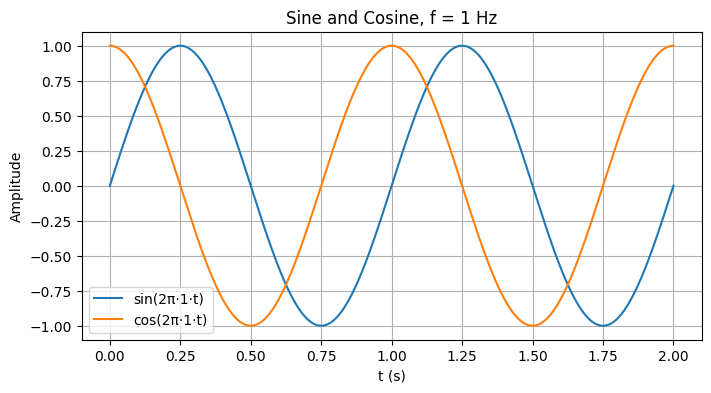

In [2]:
#1b

t = np.linspace(0, 2, 1000)

x_sin = make_sinusoid('sin', 1, 1, 0, t)
x_cos = make_sinusoid('cos', 1, 1, 0, t)

plt.figure(figsize=(8, 4))
plt.plot(t, x_sin, label="sin(2π·1·t)")
plt.plot(t, x_cos, label="cos(2π·1·t)")
plt.xlabel("t (s)")
plt.ylabel("Amplitude")
plt.title("Sine and Cosine, f = 1 Hz")
plt.legend()
plt.grid(True)
plt.show()


In [3]:
#1c

for f in [1, 3.5, 10]:
    cos_val = make_sinusoid('cos', 1, f, 0, t)
    sin_val = make_sinusoid('sin', 1, f, np.pi/2, t)
    assert np.allclose(cos_val, sin_val, atol=1e-9), f"Mismatch at f={f}"

print("All identity tests passed: cos(x) == sin(x + pi/2)")


All identity tests passed: cos(x) == sin(x + pi/2)


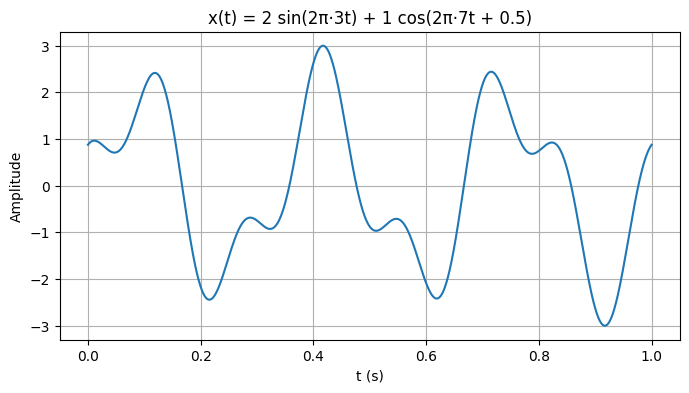

Peak-to-peak amplitude: 5.9996538348670105


In [4]:
#1d

t2 = np.linspace(0, 1, 1000)

x = (make_sinusoid('sin', 2, 3, 0, t2)
     + make_sinusoid('cos', 1, 7, 0.5, t2))

plt.figure(figsize=(8, 4))
plt.plot(t2, x)
plt.xlabel("t (s)")
plt.ylabel("Amplitude")
plt.title("x(t) = 2 sin(2π·3t) + 1 cos(2π·7t + 0.5)")
plt.grid(True)
plt.show()

print("Peak-to-peak amplitude:", np.ptp(x))


## Task 2

In [5]:
#2a

def my_dft(x):
    """
    x: real-valued 1D numpy array, length N
    returns: ReX, ImX, each of length N//2 + 1
    Implements the analysis equations directly with nested loops --
    does not use np.fft.
    """
    N = len(x)
    ReX = np.zeros(N // 2 + 1)
    ImX = np.zeros(N // 2 + 1)

    for k in range(N // 2 + 1):
        re_sum = 0.0
        im_sum = 0.0
        for n in range(N):
            angle = 2 * np.pi * k * n / N
            re_sum += x[n] * np.cos(angle)
            im_sum -= x[n] * np.sin(angle)
        ReX[k] = re_sum
        ImX[k] = im_sum

    return ReX, ImX


In [6]:
#2b

x = np.array([1, 2, 3, 4])
ReX, ImX = my_dft(x)
print("ReX:", ReX)
print("ImX:", ImX)


ReX: [10. -2. -2.]
ImX: [ 0.00000000e+00  2.00000000e+00 -9.79717439e-16]


In [7]:
#2c

expected_Re = np.array([10, -2, -2])
expected_Im = np.array([0, 2, 0])

assert np.allclose(ReX, expected_Re), "ReX does not match expected values"
assert np.allclose(ImX, expected_Im), "ImX does not match expected values"

print("DFT verified against known result.")


DFT verified against known result.


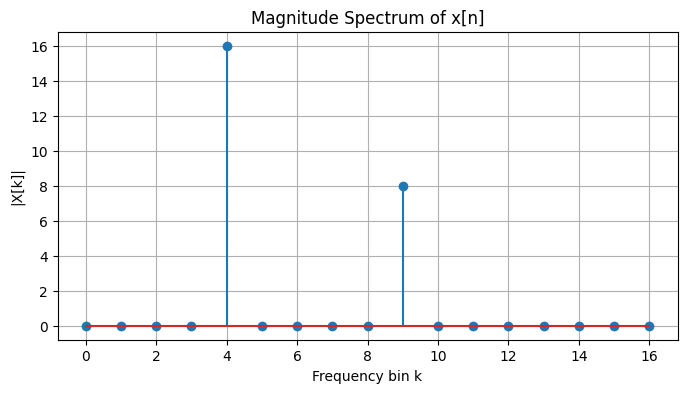

Bins with largest magnitude: [np.int64(4), np.int64(9)]
Expected peaks at k = 4 and k = 9


In [8]:
#2d

def magnitude_spectrum(ReX, ImX):
    return np.sqrt(ReX**2 + ImX**2)

N = 32
n = np.arange(N)
x_n = np.sin(2 * np.pi * 4 * n / N) + 0.5 * np.cos(2 * np.pi * 9 * n / N)

ReX_n, ImX_n = my_dft(x_n)
mag = magnitude_spectrum(ReX_n, ImX_n)

plt.figure(figsize=(8, 4))
plt.stem(np.arange(N // 2 + 1), mag)
plt.xlabel("Frequency bin k")
plt.ylabel("|X[k]|")
plt.title("Magnitude Spectrum of x[n]")
plt.grid(True)
plt.show()

peak_bins = np.argsort(mag)[-2:]
print("Bins with largest magnitude:", sorted(peak_bins))
print("Expected peaks at k = 4 and k = 9")


## Task 3

In [9]:
#3a

def my_idft(ReX, ImX, N):
    """
    ReX, ImX: half-spectrum arrays of length N//2 + 1
    N: original signal length
    returns: reconstructed real signal x[n], length N
    Implements the synthesis equation with the correct K_k scaling
    for interior bins vs DC/Nyquist bins.
    """
    x = np.zeros(N)
    num_bins = N // 2 + 1

    ReX_scaled = ReX.copy() / N
    ImX_scaled = ImX.copy() / N


    for k in range(1, num_bins):
        is_nyquist = (N % 2 == 0) and (k == N // 2)
        if not is_nyquist:
            ReX_scaled[k] *= 2
            ImX_scaled[k] *= 2

    for n in range(N):
        total = 0.0
        for k in range(num_bins):
            angle = 2 * np.pi * k * n / N
            total += ReX_scaled[k] * np.cos(angle) - ImX_scaled[k] * np.sin(angle)
        x[n] = total

    return x


In [10]:
#3b

x = np.array([1.0, 2.0, 3.0, 4.0])
ReX, ImX = my_dft(x)
x_rec = my_idft(ReX, ImX, 4)

print("Original:     ", x)
print("Reconstructed:", x_rec)

assert np.allclose(x, x_rec), "Round-trip reconstruction failed"
print("Round-trip test passed.")


Original:      [1. 2. 3. 4.]
Reconstructed: [1. 2. 3. 4.]
Round-trip test passed.


In [11]:
#3c

np.random.seed(0)

for N in [8, 16, 32, 64, 128]:
    x_rand = np.random.randn(N)
    ReX_r, ImX_r = my_dft(x_rand)
    x_rec_r = my_idft(ReX_r, ImX_r, N)
    max_err = np.max(np.abs(x_rand - x_rec_r))
    print(f"N = {N:4d}  ->  max abs reconstruction error = {max_err:.3e}")
    assert max_err < 1e-9, f"Reconstruction error too large for N={N}"

print("\nAll round-trip tests passed for all lengths.")


N =    8  ->  max abs reconstruction error = 7.216e-16
N =   16  ->  max abs reconstruction error = 1.707e-15
N =   32  ->  max abs reconstruction error = 7.772e-15
N =   64  ->  max abs reconstruction error = 1.071e-14
N =  128  ->  max abs reconstruction error = 3.331e-14

All round-trip tests passed for all lengths.
